# Actividad 5. Panel de información y visualizaciones por país

## Objetivo

Definir, calcular y auditar los **indicadores del panel por país** de la
aplicación: información general, estadísticas de desastres, impacto humano y
económico, rankings mundiales y **cobertura de los datos**. El panel se adapta
a lo que cada país reporta: cuando falta un numerador o un denominador se
muestra **«Sin datos»**, nunca un cero engañoso.

## 1. Variables e indicadores

La matriz se organiza en cinco bloques. Todos los montos están en **pesos
mexicanos** y los nombres se presentan en español.

| Bloque | Indicador | Definición | Unidad | Fuente |
|---|---|---|---|---|
| General | Población | Población total del último año disponible | habitantes | WDI |
| General | Superficie | Superficie territorial | km² | WDI |
| General | PIB | Producto interno bruto convertido a MXN | MXN | WDI |
| General | PIB por habitante | PIB / población | MXN | WDI |
| General | Densidad | Población / superficie | hab/km² | WDI |
| Desastres | Eventos | Registros en el periodo y tipo seleccionados | eventos | EM-DAT |
| Desastres | Años con registros | Años distintos con al menos un evento | años | EM-DAT |
| Desastres | Fallecidos | Suma de muertes reportadas | personas | EM-DAT |
| Desastres | Afectados | Suma de personas afectadas reportadas | personas | EM-DAT |
| Desastres | Daño económico | Suma de daños reportados | MXN | EM-DAT |
| Impacto relativo | Afectados por 100 mil hab. | Afectados / población × 100,000 | por 100 mil | EM-DAT + WDI |
| Impacto relativo | Daño sobre PIB anual | Daño acumulado / PIB × 100 | % | EM-DAT + WDI |
| Impacto relativo | Fallecidos por evento | Fallecidos / eventos | personas/evento | EM-DAT |
| Impacto relativo | Daño por evento | Daño / eventos | MXN/evento | EM-DAT |
| Impacto relativo | Daño por afectado | Daño / afectados | MXN/persona | EM-DAT |
| Impacto relativo | Eventos por año | Eventos / años del periodo | eventos/año | EM-DAT |
| Rankings | Posición mundial | Lugar entre territorios con ≥ 1 evento | puesto | EM-DAT |
| Calidad | Cobertura por campo | Eventos con fallecidos, afectados o daño reportado | % | EM-DAT |
| Calidad | Cobertura temporal | Años con registros / años del periodo | % | EM-DAT |
| Calidad | Completitud promedio | Promedio de las tres coberturas de impacto | % | EM-DAT |

### Reglas de disponibilidad

1. **Los nulos de EM-DAT no son ceros.** Un campo vacío significa «no
   reportado». Por eso el panel calcula la cobertura antes de mostrar promedios.
2. **Los ratios necesitan numerador y denominador.** Si falta población o PIB en
   el WDI, el indicador se muestra como «Sin datos» y se explica qué falta.
3. **Sin eventos no hay promedios.** Si el periodo y el tipo seleccionados no
   tienen registros, los indicadores de impacto quedan como «Sin datos».
4. **El daño es acumulado y el PIB es anual.** La razón daño/PIB es una
   referencia de magnitud, no una pérdida anual.
5. **Los afectados son acumulados.** Una misma persona puede contarse en varios
   eventos, así que la tasa por 100 mil habitantes puede superar 100,000.

## 2. Preparación

Cargo los archivos que consume la aplicación y defino las funciones de
auditoría. Las rutas salen de `src/config.py` para no duplicar ubicaciones.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.config import APP_DATOS, RESULTADOS_GRAFICAS, RESULTADOS_TABLAS

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
})

PURPURA = "#4c1d95"
ROSA = "#fa8a9a"
AMARILLO = "#ffb71b"
ROJO = "#ee3e29"
GRIS = "#7a7191"

def cargar(nombre):
    return json.loads((APP_DATOS / nombre).read_text(encoding="utf-8"))

eventos = cargar("eventos_pais.json")
socio = cargar("paises_socio.json")
filtros = cargar("filtros.json")
owid = cargar("owid.json")
geojson = cargar("paises.geojson")

EVENTOS = eventos["paises"]
SOCIOS = socio["paises"]
PERIODO = filtros["periodo"]
print(f"Periodo del panel: {PERIODO['inicio']}–{PERIODO['fin']}")
print(f"Eventos: {eventos['meta']['n_eventos']:,} · territorios: {eventos['meta']['n_paises']}")
print(f"Países con WDI: {len(SOCIOS)} · territorios dibujables: {len(geojson['features'])}")

Periodo del panel: 2000–2026
Eventos: 10,907 · territorios: 220
Países con WDI: 267 · territorios dibujables: 175


## 3. Universo y disponibilidad

Antes de calcular indicadores reviso qué se puede calcular para cada país.
EM-DAT cubre **220 territorios**, pero el WDI no reporta población y PIB para
algunos de ellos y el GeoJSON solo dibuja 175 unidades. El panel abre los
territorios del mapa; la auditoría conserva los 220 para no ocultar la
cobertura real del dataset.

Los campos de impacto tienen coberturas muy distintas: los afectados suelen
estar mejor reportados que el daño económico. Esa diferencia es la razón de
mostrar una cobertura por campo en el panel.

In [2]:
def cobertura_pais(codigo):
    filas = EVENTOS.get(codigo, [])
    total = len(filas)
    periodo = PERIODO["fin"] - PERIODO["inicio"] + 1
    if not total:
        return {
            "codigo": codigo, "eventos": 0, "anios": 0, "periodo": periodo,
            "cobertura_temporal": None,
            "cobertura_fallecidos": None, "cobertura_afectados": None,
            "cobertura_dano": None, "completitud": None,
        }
    cuenta = [sum(1 for f in filas if f[i] is not None) for i in (2, 3, 4)]
    anios = len({f[0] for f in filas})
    return {
        "codigo": codigo,
        "eventos": total,
        "anios": anios,
        "periodo": periodo,
        "cobertura_temporal": 100 * anios / periodo,
        "cobertura_fallecidos": 100 * cuenta[0] / total,
        "cobertura_afectados": 100 * cuenta[1] / total,
        "cobertura_dano": 100 * cuenta[2] / total,
        "completitud": 100 * sum(cuenta) / (3 * total),
    }

def nivel_calidad(completitud):
    if completitud is None:
        return "Sin registros"
    if completitud >= 65:
        return "Alta"
    if completitud >= 40:
        return "Media"
    return "Baja"

tabla_cobertura = pd.DataFrame([cobertura_pais(c) for c in EVENTOS])
tabla_cobertura["nivel"] = tabla_cobertura["completitud"].map(nivel_calidad)
tabla_cobertura["tiene_wdi"] = tabla_cobertura["codigo"].isin(SOCIOS)
tabla_cobertura["en_mapa"] = tabla_cobertura["codigo"].isin(
    {f["properties"]["codigo"] for f in geojson["features"]}
)

RESULTADOS_TABLAS.mkdir(parents=True, exist_ok=True)
salida = RESULTADOS_TABLAS / "actividad5_cobertura_pais.csv"
tabla_cobertura.to_csv(salida, index=False, float_format="%.2f")
print(f"Tabla guardada: {salida.relative_to(RAIZ)}")
print(f"Territorios sin WDI: {(~tabla_cobertura['tiene_wdi']).sum()}")
print(f"Territorios fuera del mapa: {(~tabla_cobertura['en_mapa']).sum()}")
tabla_cobertura.head(8).round(1)

Tabla guardada: resultados\tablas\actividad5_cobertura_pais.csv
Territorios sin WDI: 17
Territorios fuera del mapa: 52


,codigo,eventos,anios,periodo,cobertura_temporal,cobertura_fallecidos,cobertura_afectados,cobertura_dano,completitud,nivel,tiene_wdi,en_mapa
0,AFG,182,27,27,100.0,90.1,77.5,6.0,57.9,Media,True,True
1,AGO,66,24,27,88.9,77.3,90.9,3.0,57.1,Media,True,True
2,AIA,1,1,27,3.7,100.0,100.0,100.0,100.0,Alta,False,False
3,ALB,30,18,27,66.7,53.3,83.3,16.7,51.1,Media,True,True
4,ARE,3,2,27,7.4,33.3,66.7,0.0,33.3,Baja,True,True
5,ARG,89,27,27,100.0,56.2,84.3,25.8,55.4,Media,True,True
6,ARM,11,10,27,37.0,27.3,90.9,36.4,51.5,Media,True,True
7,ASM,4,4,27,14.8,50.0,75.0,50.0,58.3,Media,True,False


In [3]:
columnas = ["cobertura_fallecidos", "cobertura_afectados", "cobertura_dano", "cobertura_temporal", "completitud"]
resumen = tabla_cobertura[columnas].describe(percentiles=[0.25, 0.5, 0.75]).T
resumen = resumen[["min", "25%", "50%", "75%", "max"]].round(1)
resumen.columns = ["Mínimo", "P25", "Mediana", "P75", "Máximo"]
resumen

,Mínimo,P25,Mediana,P75,Máximo
cobertura_fallecidos,0.0,47.0,61.5,76.9,100.0
cobertura_afectados,0.0,66.7,86.3,93.8,100.0
cobertura_dano,0.0,6.6,17.2,36.5,100.0
cobertura_temporal,3.7,25.0,63.0,88.9,100.0
completitud,16.7,44.4,55.2,60.2,100.0


In [4]:
ejemplos = ["MEX", "USA", "HTI", "AFG", "TUV", "TWN"]
columnas = ["codigo", "eventos", "anios", "cobertura_temporal", "cobertura_fallecidos", "cobertura_afectados", "cobertura_dano", "completitud", "nivel"]
tabla_cobertura[tabla_cobertura["codigo"].isin(ejemplos)].set_index("codigo").loc[ejemplos, columnas[1:]].round(1)

,eventos,anios,cobertura_temporal,cobertura_fallecidos,cobertura_afectados,cobertura_dano,completitud,nivel
codigo,,,,,,,,
MEX,171,27,100.0,84.2,76.6,39.8,66.9,Alta
USA,660,27,100.0,77.0,62.7,76.1,71.9,Alta
HTI,100,27,100.0,86.0,91.0,14.0,63.7,Media
AFG,182,27,100.0,90.1,77.5,6.0,57.9,Media
TUV,4,4,14.8,0.0,75.0,0.0,25.0,Baja
TWN,75,26,96.3,82.7,72.0,73.3,76.0,Alta


### Niveles de calidad

La completitud promedio permite resumir la cobertura en tres niveles:

| Nivel | Completitud promedio | Interpretación |
|---|---:|---|
| **Alta** | ≥ 65 % | Los tres campos están bien reportados; los promedios son confiables. |
| **Media** | 40–65 % | Hay datos suficientes para describir, pero algún campo está subrepresentado. |
| **Baja** | < 40 % | Los promedios deben leerse como una cota mínima. |

El umbral no es una verdad absoluta: es una señal para que el usuario sepa
cuánto pesa el silencio de la fuente. En el panel se muestra junto a la
cobertura de cada campo.

In [5]:
conteo_nivel = tabla_cobertura["nivel"].value_counts().reindex(["Alta", "Media", "Baja", "Sin registros"]).fillna(0).astype(int)
print(conteo_nivel.to_string())
print()
print("Menor completitud (con al menos 5 eventos):")
columnas = ["codigo", "eventos", "cobertura_fallecidos", "cobertura_afectados", "cobertura_dano", "completitud", "nivel"]
tabla_cobertura.query("eventos >= 5").nsmallest(8, "completitud")[columnas].round(1)

nivel
Alta              26
Media            161
Baja              33
Sin registros      0

Menor completitud (con al menos 5 eventos):


,codigo,eventos,cobertura_fallecidos,cobertura_afectados,cobertura_dano,completitud,nivel
152,PLW,5,0.0,80.0,0.0,26.7,Baja
113,LVA,13,61.5,15.4,7.7,28.2,Baja
111,LTU,14,71.4,0.0,14.3,28.6,Baja
128,MNP,7,42.9,42.9,0.0,28.6,Baja
112,LUX,8,62.5,12.5,12.5,29.2,Baja
14,BEL,41,61.0,22.0,14.6,32.5,Baja
45,CYM,8,12.5,12.5,75.0,33.3,Baja
60,FIN,5,80.0,20.0,0.0,33.3,Baja


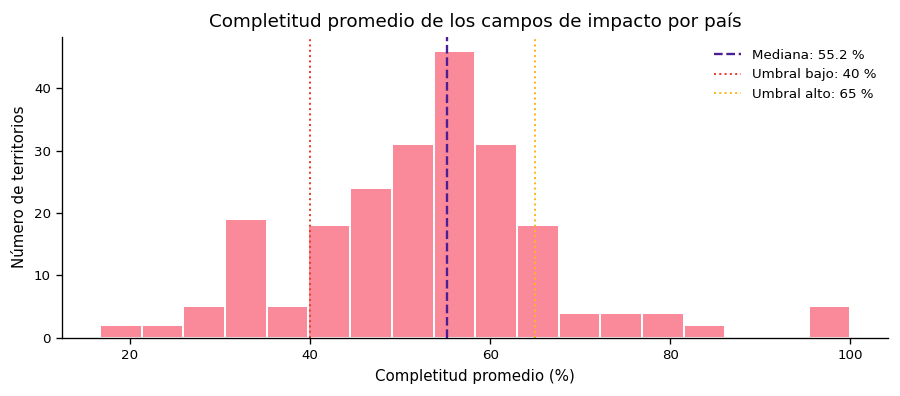

Gráfica guardada: resultados\graficas\actividad5_panel_completitud.png


In [6]:
fig, ax = plt.subplots(figsize=(7.6, 3.4))
datos = tabla_cobertura["completitud"].dropna()
ax.hist(datos, bins=18, color=ROSA, edgecolor="#ffffff", linewidth=1.2)
ax.axvline(datos.median(), color=PURPURA, linestyle="--", linewidth=1.4, label=f"Mediana: {datos.median():.1f} %")
ax.axvline(40, color=ROJO, linestyle=":", linewidth=1.2, label="Umbral bajo: 40 %")
ax.axvline(65, color=AMARILLO, linestyle=":", linewidth=1.2, label="Umbral alto: 65 %")
ax.set_title("Completitud promedio de los campos de impacto por país")
ax.set_xlabel("Completitud promedio (%)")
ax.set_ylabel("Número de territorios")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
ruta = RESULTADOS_GRAFICAS / "actividad5_panel_completitud.png"
fig.savefig(ruta, bbox_inches="tight")
plt.show()
print(f"Gráfica guardada: {ruta.relative_to(RAIZ)}")

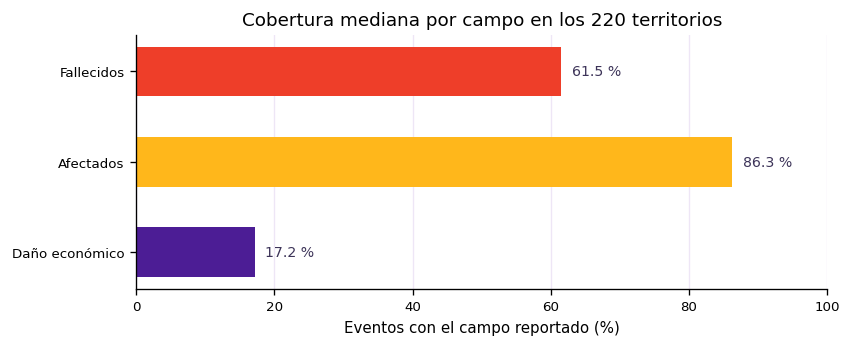

Gráfica guardada: resultados\graficas\actividad5_panel_cobertura_campos.png


In [7]:
medianas = tabla_cobertura[["cobertura_fallecidos", "cobertura_afectados", "cobertura_dano"]].median()
etiquetas = ["Fallecidos", "Afectados", "Daño económico"]
colores = [ROJO, AMARILLO, PURPURA]

fig, ax = plt.subplots(figsize=(7.2, 3.0))
barras = ax.barh(etiquetas[::-1], medianas.values[::-1], color=colores[::-1], height=0.55)
for barra, valor in zip(barras, medianas.values[::-1]):
    ax.text(valor + 1.5, barra.get_y() + barra.get_height() / 2, f"{valor:.1f} %", va="center", fontsize=8.5, color="#3c3358")
ax.set_xlim(0, 100)
ax.set_title("Cobertura mediana por campo en los 220 territorios")
ax.set_xlabel("Eventos con el campo reportado (%)")
ax.grid(axis="x", color="#eee6f6", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
ruta = RESULTADOS_GRAFICAS / "actividad5_panel_cobertura_campos.png"
fig.savefig(ruta, bbox_inches="tight")
plt.show()
print(f"Gráfica guardada: {ruta.relative_to(RAIZ)}")

## 4. Indicadores derivados

Los indicadores relativos permiten comparar países de tamaños muy distintos.
Se calculan con los totales del periodo completo (2000–2026) y el WDI más
reciente (2024). En la aplicación se recalculan con el periodo y el tipo que
elija el usuario.

| Indicador | Fórmula | Lectura |
|---|---|---|
| Afectados por 100 mil | `afectados / población × 100,000` | Intensidad humana acumulada |
| Daño sobre PIB | `daño / PIB × 100` | Peso económico acumulado |
| Fallecidos por evento | `fallecidos / eventos` | Letalidad promedio |
| Daño por evento | `daño / eventos` | Costo promedio |
| Daño por afectado | `daño / afectados` | Costo implícito por persona |
| Eventos por año | `eventos / 27` | Frecuencia anual |

Los tres primeros son los que mejor resisten la comparación internacional.
El daño por afectado solo se calcula cuando ambos campos existen, porque
mezclar un total reportado con un denominador incompleto produce un cociente
sin interpretación.

In [8]:
def indicadores_pais(codigo):
    filas = EVENTOS.get(codigo, [])
    s = SOCIOS.get(codigo, {})
    total = len(filas)
    fallecidos = sum(f[2] or 0 for f in filas)
    afectados = sum(f[3] or 0 for f in filas)
    dano = sum(f[4] or 0 for f in filas)
    anios = PERIODO["fin"] - PERIODO["inicio"] + 1
    con_fallecidos = sum(1 for f in filas if f[2] is not None)
    con_afectados = sum(1 for f in filas if f[3] is not None)
    con_dano = sum(1 for f in filas if f[4] is not None)

    def ratio(numerador, denominador, factor=1.0):
        if not total or not denominador:
            return None
        return factor * numerador / denominador

    return {
        "codigo": codigo,
        "eventos": total,
        "poblacion": s.get("poblacion"),
        "pib_mxn": s.get("pib_mxn"),
        "afectados_100k": ratio(afectados, s.get("poblacion"), 100_000) if con_afectados else None,
        "dano_pib_pct": ratio(dano, s.get("pib_mxn"), 100) if con_dano else None,
        "fallecidos_evento": ratio(fallecidos, total) if con_fallecidos else None,
        "dano_evento": ratio(dano, total) if con_dano else None,
        "dano_afectado": ratio(dano, afectados) if con_dano and con_afectados and afectados else None,
        "eventos_anio": ratio(total, anios),
    }

tabla_indicadores = pd.DataFrame([indicadores_pais(c) for c in EVENTOS])
salida = RESULTADOS_TABLAS / "actividad5_indicadores_pais.csv"
tabla_indicadores.to_csv(salida, index=False, float_format="%.4f")
print(f"Tabla guardada: {salida.relative_to(RAIZ)}")

columnas = ["codigo", "eventos", "afectados_100k", "dano_pib_pct", "fallecidos_evento", "dano_evento", "eventos_anio"]
tabla_indicadores[tabla_indicadores["codigo"].isin(ejemplos)].set_index("codigo").loc[ejemplos, columnas[1:]].round(2)

Tabla guardada: resultados\tablas\actividad5_indicadores_pais.csv


,eventos,afectados_100k,dano_pib_pct,fallecidos_evento,dano_evento,eventos_anio
codigo,,,,,,
MEX,171,11874.13,4.20,15.39,9.360875e+09,6.33
USA,660,30795.19,7.15,17.65,6.601071e+10,24.44
HTI,100,138623.16,72.19,2405.75,3.641879e+09,3.70
AFG,182,87827.71,3.76,105.26,7.647086e+07,6.74
TUV,4,210626.17,NaN,NaN,NaN,0.15
TWN,75,NaN,NaN,21.57,3.589772e+09,2.78


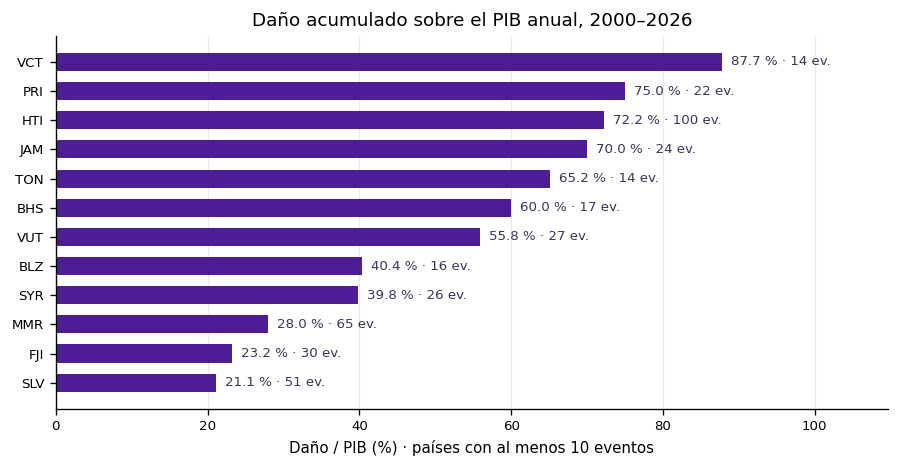

Gráfica guardada: resultados\graficas\actividad5_panel_dano_pib.png


In [9]:
validos = tabla_indicadores.dropna(subset=["dano_pib_pct"]).query("eventos >= 10")
top = validos.nlargest(12, "dano_pib_pct").sort_values("dano_pib_pct")

fig, ax = plt.subplots(figsize=(7.6, 4.0))
barras = ax.barh(top["codigo"], top["dano_pib_pct"], color=PURPURA, height=0.62)
for barra, valor, eventos_pais in zip(barras, top["dano_pib_pct"], top["eventos"]):
    ax.text(valor + 1.2, barra.get_y() + barra.get_height() / 2, f"{valor:.1f} % · {eventos_pais} ev.", va="center", fontsize=8, color="#3c3358")
ax.set_xlim(0, top["dano_pib_pct"].max() * 1.25)
ax.set_title("Daño acumulado sobre el PIB anual, 2000–2026")
ax.set_xlabel("Daño / PIB (%) · países con al menos 10 eventos")
ax.grid(axis="x", color="#eee6f6", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
ruta = RESULTADOS_GRAFICAS / "actividad5_panel_dano_pib.png"
fig.savefig(ruta, bbox_inches="tight")
plt.show()
print(f"Gráfica guardada: {ruta.relative_to(RAIZ)}")

## 5. Adaptación a los datos disponibles

La app aplica estas reglas en cada render del modal:

| Situación | Qué muestra el panel |
|---|---|
| País sin población o PIB en WDI (p. ej. Taiwán) | KPIs generales y ratios como «Sin datos»; se explica que falta WDI |
| Periodo sin eventos (p. ej. Turkmenistán desde 2020) | Eventos = 0; impacto y promedios como «Sin datos»; gráficas con aviso |
| Eventos sin fallecidos reportados | KPI de fallecidos como «Sin datos»; no se muestra un cero |
| Eventos sin daño reportado | Daño y ratios económicos como «Sin datos»; la cobertura lo indica |
| Cobertura baja | Insignia «Baja» y nota de que los promedios son una cota mínima |
| País fuera del GeoJSON | No aparece en el mapa; el panel se abre solo para los territorios dibujables |

La tercera y cuarta fila son la diferencia clave entre «no hubo» y «no se
reportó». El panel nunca imputa cero a un campo vacío.

In [10]:
# Taiwán: tiene eventos y mapa, pero no WDI.
twn = indicadores_pais("TWN")
assert twn["poblacion"] is None and twn["pib_mxn"] is None
assert twn["afectados_100k"] is None and twn["dano_pib_pct"] is None
assert twn["fallecidos_evento"] is not None

# Tuvalu: tiene eventos, pero no reporta fallecidos ni daño.
tuv = indicadores_pais("TUV")
assert tuv["fallecidos_evento"] is None
assert tuv["dano_evento"] is None
assert tuv["afectados_100k"] is not None

# México: los ratios se calculan porque tiene WDI y eventos.
mex = indicadores_pais("MEX")
assert mex["afectados_100k"] > 0 and mex["dano_pib_pct"] > 0
assert mex["fallecidos_evento"] > 0

print("México:", {k: (round(v, 2) if isinstance(v, float) else v) for k, v in mex.items()})
print("Taiwán:", {k: (round(v, 2) if isinstance(v, float) else v) for k, v in twn.items()})
print("Tuvalu:", {k: (round(v, 2) if isinstance(v, float) else v) for k, v in tuv.items()})
print("\nValidaciones de disponibilidad: OK")

México: {'codigo': 'MEX', 'eventos': 171, 'poblacion': 130861007.0, 'pib_mxn': 38074177670649.0, 'afectados_100k': 11874.13, 'dano_pib_pct': 4.2, 'fallecidos_evento': 15.39, 'dano_evento': 9360874573.1, 'dano_afectado': 103015.04, 'eventos_anio': 6.33}
Taiwán: {'codigo': 'TWN', 'eventos': 75, 'poblacion': None, 'pib_mxn': None, 'afectados_100k': None, 'dano_pib_pct': None, 'fallecidos_evento': 21.57, 'dano_evento': 3589771882.67, 'dano_afectado': 88545.86, 'eventos_anio': 2.78}
Tuvalu: {'codigo': 'TUV', 'eventos': 4, 'poblacion': 9646.0, 'pib_mxn': 1180447129.0, 'afectados_100k': 210626.17, 'dano_pib_pct': None, 'fallecidos_evento': None, 'dano_evento': None, 'dano_afectado': None, 'eventos_anio': 0.15}

Validaciones de disponibilidad: OK


## 6. Integración con la aplicación

El panel no vuelve a calcular los datos en el servidor: recibe los JSON ya
agregados y resuelve los filtros en el navegador. Esta celda comprueba que el
markup, las funciones y los archivos necesarios sigan existiendo, y que los
totales de México coincidan con `filtros.json`.

In [11]:
html = (RAIZ / "app" / "index.html").read_text(encoding="utf-8")
js = (RAIZ / "app" / "js" / "app.js").read_text(encoding="utf-8")
css = (RAIZ / "app" / "css" / "estilos.css").read_text(encoding="utf-8")

piezas = {
    "bloque de indicadores": 'id="modal-indicadores"' in html,
    "bloque de calidad": 'id="modal-calidad"' in html,
    "gráfica de daño": 'id="graf-dano"' in html,
    "selector de medida": 'id="tipos-metrica"' in html,
    "función calidadPais": "function calidadPais" in js,
    "función indicadoresImpacto": "function indicadoresImpacto" in js,
    "función pintarCalidad": "function pintarCalidad" in js,
    "avisos de gráfica vacía": "function marcarGraficoVacio" in js,
    "estado sin datos": "Sin datos" in js,
    "estilos de indicadores": ".indicador__valor" in css,
}
for nombre, presente in piezas.items():
    print(f"{'OK ' if presente else 'FALTA'} · {nombre}")
assert all(piezas.values())

# Totales de México en el JSON agregado que consume la app.
filas_mex = filtros["datos"]["MEX"]
eventos_mex = sum(f[2] for f in filas_mex)
fallecidos_mex = sum(f[3] for f in filas_mex)
afectados_mex = sum(f[4] for f in filas_mex)
dano_mex = sum(f[5] for f in filas_mex)
assert eventos_mex == 171
assert (fallecidos_mex, afectados_mex) == (2631, 15_538_601)
assert round(dano_mex) == 1_600_709_552_000

print("\nMéxico en filtros.json:")
print(f"  Eventos: {eventos_mex} · Fallecidos: {fallecidos_mex:,}")
print(f"  Afectados: {afectados_mex:,} · Daño: {dano_mex / 1e12:,.2f} billones MXN")
print("\nIntegración con la app: OK")

OK  · bloque de indicadores
OK  · bloque de calidad
OK  · gráfica de daño
OK  · selector de medida
OK  · función calidadPais
OK  · función indicadoresImpacto
OK  · función pintarCalidad
OK  · avisos de gráfica vacía
OK  · estado sin datos
OK  · estilos de indicadores

México en filtros.json:
  Eventos: 171 · Fallecidos: 2,631
  Afectados: 15,538,601 · Daño: 1.60 billones MXN

Integración con la app: OK


## 7. Conclusiones

* El panel cubre **220 territorios** y 10,907 eventos, pero la disponibilidad no
  es homogénea: solo 201 territorios tienen población y PIB para calcular
  ratios, y el daño económico se reporta en una fracción menor de los eventos.
* Los **indicadores relativos** resuelven la comparación entre países de
  escalas distintas: afectados por 100 mil habitantes, daño sobre PIB,
  fallecidos por evento y daño por evento.
* La **cobertura por campo** es parte del dato, no un adorno: distingue «no
  hubo» de «no se reportó» y permite leer los promedios con cautela.
* La adaptación se implementa con estados explícitos: «Sin datos», avisos en
  las gráficas y una insignia de calidad. Nunca se imputa cero a un campo
  vacío.
* La vista mundial y la vista estatal de México se mantienen separadas por
  metodología (EM-DAT vs. CENAPRED), tal como se documenta en el notebook 05.